# Assignment 2:
### Hierarchical Clustering
Date: September 24, 2026

Report produced by:  
COMP 3705 Group 3

## Load the data and inspect the header

In [23]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("CC GENERAL.csv")

df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [24]:
df.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


## Meanings of Columns

***CUST_ID*** - Unique customer ID to identify each customer

***BALANCE*** - Customer's balance left in their account to make purchases

***BALANCE_FREQUENCY*** - How frequently the balance is updated (1 = frequently updated, 0 = not frequently updated)

***PURCHASES*** - The number of purchases made by the customer

***ONEOFF_PURCHASES*** - Customer's maximum purchase amount done in one go

***INSTALLMENTS_PURCHASES*** - Number of installment purchases

***CASH_ADVANCE*** - Cash advance amount given to the customer

***PURCHASES_FREQUENCY*** - How frequently purchases are being made (1 = frequently purchased, 0 = not frequently purchased)

***ONEOFF_PURCHASES_FREQUENCY*** - How frequently purchases are happening in one go (1 = frequently purchased, 0 = not frequently purchased)

***PURCHASES_INSTALLMENTS_FREQUENCY*** - How frequently installment purchases are being made (1 = frequently done, 0 = not frequently done)

***CASH_ADVANCE_FREQUENCY*** - How frequently cash advances are being paid

***CASH_ADVANCE_TRX*** - How frequently cash advance transactions are being made

***PURCHASES_TRX*** - Number of purchase transactions made

***CREDIT_LIMIT*** - Customer's credit card limit

***PAYMENTS*** - Amount the customer paid into the credit card

***MINIMUM_PAYMENTS*** - Amount of minimum payments made by the customer

***PRC_FULL_PAYMENT*** - Percentage of the full payment made by the customer to the credit card

***TENURE*** - How long the customer has had the credit card

## Observations 
- The data has 8,950 rows x 18 columns. 
- More than half of the customers (about 52%) never took a cash advance. About 48% made no one-off purchases, about 44% made no installment purchases and about 23% made no purchases at all.
- PURCHASES has a mean of 1,003 and a median of 361 with a max. of about 49,040. CASH_ADVANCE has a mean of around 979 but a median of 0. MINIMUM_PAYMENTS reaches about 76,406 against a median of about 312. this indicates that these money columns are mostly right skewed.
- PRC_FULL_PAYMENT has a median of 0 this means more than have of the customers paid their card bills.
- 

## Check Datatypes Missing Values, & Duplicate Rows

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
CUST_ID                             8950 non-null object
BALANCE                             8950 non-null float64
BALANCE_FREQUENCY                   8950 non-null float64
PURCHASES                           8950 non-null float64
ONEOFF_PURCHASES                    8950 non-null float64
INSTALLMENTS_PURCHASES              8950 non-null float64
CASH_ADVANCE                        8950 non-null float64
PURCHASES_FREQUENCY                 8950 non-null float64
ONEOFF_PURCHASES_FREQUENCY          8950 non-null float64
PURCHASES_INSTALLMENTS_FREQUENCY    8950 non-null float64
CASH_ADVANCE_FREQUENCY              8950 non-null float64
CASH_ADVANCE_TRX                    8950 non-null int64
PURCHASES_TRX                       8950 non-null int64
CREDIT_LIMIT                        8949 non-null float64
PAYMENTS                            8950 non-null float64
MINIMUM_PAYMENTS            

In [26]:
df.isna().sum()

CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

In [27]:
df.duplicated().sum()

0

In [28]:
df_cc_cleaned = df.copy()

# MINIMUM_PAYMENTS is missing and PAYMENTS = 0 → fill with 0
df_cc_cleaned.loc[
    df_cc_cleaned['MINIMUM_PAYMENTS'].isna() &
    (df_cc_cleaned['PAYMENTS'] == 0),
    'MINIMUM_PAYMENTS'
] = 0

# MINIMUM_PAYMENTS is missing and PAYMENTS > 0 → fill with median
minimum_payments_median = df_cc_cleaned['MINIMUM_PAYMENTS'].median()

df_cc_cleaned.loc[
    df_cc_cleaned['MINIMUM_PAYMENTS'].isna() &
    (df_cc_cleaned['PAYMENTS'] > 0),
    'MINIMUM_PAYMENTS'
] = minimum_payments_median

# drop Row without Credit Limit 
df_cc_cleaned = df_cc_cleaned.dropna(subset=['CREDIT_LIMIT'])

df_cc_cleaned

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,0.000000,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
5,C10006,1809.828751,1.000000,1333.28,0.00,1333.28,0.000000,0.666667,0.000000,0.583333,0.000000,0,8,1800.0,1400.057770,2407.246035,0.000000,12
6,C10007,627.260806,1.000000,7091.01,6402.63,688.38,0.000000,1.000000,1.000000,1.000000,0.000000,0,64,13500.0,6354.314328,198.065894,1.000000,12
7,C10008,1823.652743,1.000000,436.20,0.00,436.20,0.000000,1.000000,0.000000,1.000000,0.000000,0,12,2300.0,679.065082,532.033990,0.000000,12
8,C10009,1014.926473,1.000000,861.49,661.49,200.00,0.000000,0.333333,0.083333,0.250000,0.000000,0,5,7000.0,688.278568,311.963409,0.000000,12
9,C10010,152.225975,0.545455,1281.60,1281.60,0.00,0.000000,0.166667,0.166667,0.000000,0.000000,0,3,11000.0,1164.770591,100.302262,0.000000,12


In [29]:
df_features = df_cc_cleaned.drop(columns="CUST_ID")
df_labels = df["CUST_ID"]
df_labels

0       C10001
1       C10002
2       C10003
3       C10004
4       C10005
5       C10006
6       C10007
7       C10008
8       C10009
9       C10010
10      C10011
11      C10012
12      C10013
13      C10014
14      C10015
15      C10016
16      C10017
17      C10018
18      C10019
19      C10020
20      C10021
21      C10022
22      C10023
23      C10024
24      C10025
25      C10026
26      C10027
27      C10028
28      C10029
29      C10030
         ...  
8920    C19161
8921    C19162
8922    C19163
8923    C19164
8924    C19165
8925    C19166
8926    C19167
8927    C19168
8928    C19169
8929    C19170
8930    C19171
8931    C19172
8932    C19173
8933    C19174
8934    C19175
8935    C19176
8936    C19177
8937    C19178
8938    C19179
8939    C19180
8940    C19181
8941    C19182
8942    C19183
8943    C19184
8944    C19185
8945    C19186
8946    C19187
8947    C19188
8948    C19189
8949    C19190
Name: CUST_ID, Length: 8950, dtype: object

Since we plan to run the dataset through unsupervised learning algorithms, the column CUST_ID, which is the data's label and contains unique identifiers for each customer, needs to be dropped from the dataset.  
This will ensure the model doesn't use the labels as part of its learning.

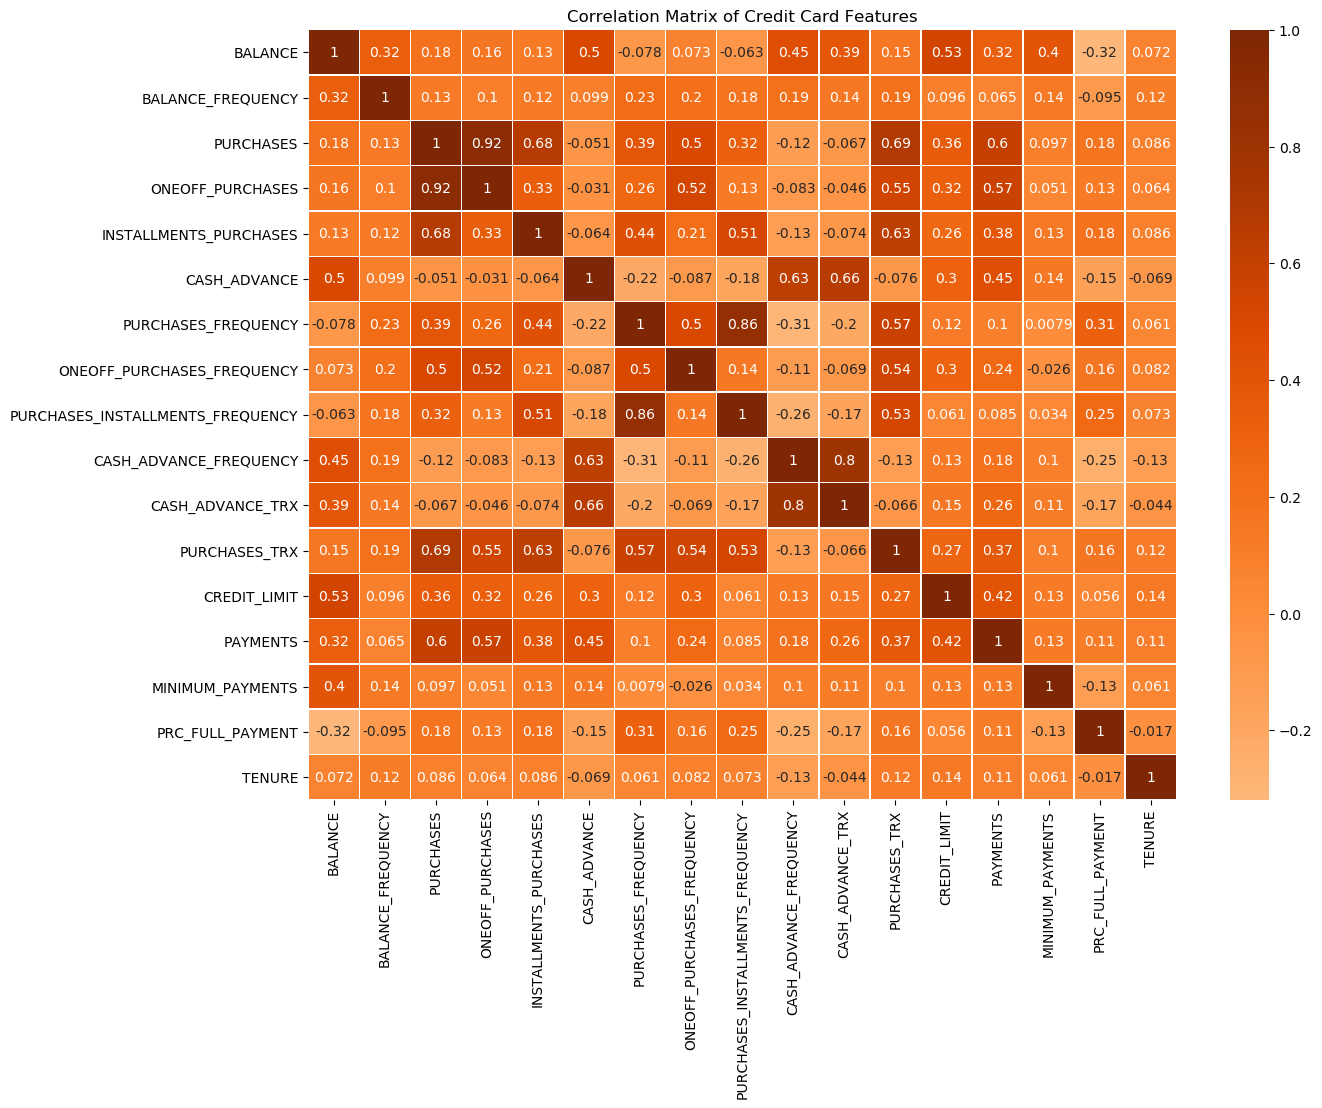

In [30]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    df_features.corr(),
    annot=True,
    cmap="Oranges",
    center=0,
    linewidths=0.3
)

plt.title("Correlation Matrix of Credit Card Features")
plt.show()

In [31]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler as scaler
from sklearn.cluster import AgglomerativeClustering as ac
from sklearn.metrics import silhouette_score as s_score, silhouette_samples as s_samples

def scale_df(df):
    return scaler().fit_transform(df)

def agglomerative_clustering(x_val, min_clusters=2, max_clusters=3, distance_metric=["euclidean"], linkage=["ward"], max_linkage_distance=[None]):
    # Create containers for results
    iteration = 0
    ac_metrics = {}

    # Sets min_clusters to 1 if value passed is lower
    if min_clusters < 1:
        min_clusters = 1
    
    for num in range(min_clusters, max_clusters+1):
        for distance in distance_metric:
            for link in linkage:
                if link == "ward" and distance != "euclidean":
                    continue
                for threshold in max_linkage_distance:
                    if threshold != None:
                        if num != min_clusters:
                            continue
                        model = ac(n_clusters=None, affinity=distance, linkage=link, distance_threshold=threshold, compute_full_tree=True).fit(x_val)
                    else:
                        model = ac(n_clusters=num, affinity=distance, linkage=link).fit(x_val)

                    iteration += 1
                    labels = model.labels_
                    metrics = {"n_clusters": "None" if threshold != None else num,
                                "distance_metric": distance,
                                "linkage": link,
                                "distance_threshold": threshold,
                                "Silhouette Score": s_score(x_val,labels,metric=distance),
                                "Silhouette Coefficients": s_samples(x_val,labels,metric=distance),
                                "Labels": model.labels_,
                                "Clusters Found": model.n_clusters_,
                                "Merge History": model.children_,
                            }
                    ac_metrics[f"Iteration {iteration}"] = metrics
    return ac_metrics

df_scaled = scale_df(df_features)
ac_metrics = agglomerative_clustering(df_scaled, 3, 5, ["euclidean", "manhattan"],["ward", "average"],[10, 20, None])
df_sklearn = pd.DataFrame(ac_metrics).transpose().drop(columns=["Labels", "Merge History", "Silhouette Coefficients"])

In [32]:
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import silhouette_score

def scipy_modeling(features_scaled):
    # Create the hierarchical tree
    Z = linkage(features_scaled, method="ward")
    
    # Create 10 different model settings
    models = [
        (2, "maxclust", 2),
        (3, "maxclust", 2),
        (4, "maxclust", 2),
        (5, "maxclust", 2),
        (6, "maxclust", 2),
        (20, "distance", 2),
        (22, "distance", 2),
        (25, "distance", 2),
        (1.0, "inconsistent", 2),
        (1.0, "inconsistent", 3)
    ]
    
    # Empty list for storing results
    results = []
    
    # Run all 10 models
    for i, (t, criterion, depth) in enumerate(models, start=1):
        clusters = fcluster(
            Z,
            t=t,
            criterion=criterion,
            depth=depth
        )
        number_of_clusters = len(np.unique(clusters))
        if number_of_clusters > 1:
            score = silhouette_score(features_scaled, clusters)
        else:
            score = None
        results.append({
            "Model": i,
            "t": t,
            "Criterion": criterion,
            "Depth": depth,
            "Number of Clusters": number_of_clusters,
            "Silhouette Score": score
        })
    return results

scipy_results = scipy_modeling(df_scaled)
df_scipy = pd.DataFrame(scipy_results)

In [33]:
df_sklearn

,Clusters Found,Silhouette Score,distance_metric,distance_threshold,linkage,n_clusters
Iteration 1,210,0.106767,euclidean,10,ward,None
Iteration 2,71,0.121515,euclidean,20,ward,None
Iteration 3,3,0.176718,euclidean,None,ward,3
Iteration 4,26,0.553238,euclidean,10,average,None
Iteration 5,5,0.788134,euclidean,20,average,None
Iteration 6,3,0.81259,euclidean,None,average,3
Iteration 7,283,0.106728,manhattan,10,average,None
Iteration 8,46,0.285204,manhattan,20,average,None
Iteration 9,3,0.769633,manhattan,None,average,3
Iteration 10,4,0.178251,euclidean,None,ward,4


In [34]:
df_scipy

,Criterion,Depth,Model,Number of Clusters,Silhouette Score,t
0,maxclust,2,1,2,0.181361,2.0
1,maxclust,2,2,3,0.176718,3.0
2,maxclust,2,3,4,0.178251,4.0
3,maxclust,2,4,5,0.131958,5.0
4,maxclust,2,5,6,0.156237,6.0
5,distance,2,6,71,0.121515,20.0
6,distance,2,7,62,0.122276,22.0
7,distance,2,8,51,0.122953,25.0
8,inconsistent,2,9,3026,0.143295,1.0
9,inconsistent,3,10,3707,0.159219,1.0


## Acknowledgment of Contributions
### Group 3 Members:  
Sebastian Levy  
Idongesit Orok  
Miracle Okojie  

### Task Distribution:  


We, Group 3, acknowledge that we understand all parts of this assignment, including those which we did not personally carry out.